# Análise Exploratória de Dados — Sucesso Comercial de Imóveis

Este notebook reúne toda a análise: preparação dos dados, tabelas, gráficos, interpretações e conclusões. Os dados processados permanecem em memória e todos os resultados são exibidos nas células, sem gerar arquivos externos.

## Como executar

Disponibilize `imoveis.csv`, `contatos.csv` e `cadastros.csv` junto ao notebook, abra-o com essa pasta como diretório de trabalho e execute **Run All / Executar tudo**. Nomes com inicial maiúscula também são aceitos. Não há configuração de pastas de entrada ou saída.

Ambiente validado: Python 3.13. Se necessário, instale as bibliotecas em uma célula separada:

```python
%pip install pandas==3.0.3 numpy==2.4.6 matplotlib==3.11.2 scipy==1.17.1 ipython==9.17.1
```

Os CSVs usam ponto e vírgula como separador. Todo o código está neste notebook; não são necessários scripts ou bases processadas previamente. Ao salvar o próprio notebook, suas saídas ficam incorporadas ao `.ipynb` para leitura posterior.

## Objetivo e regra do alvo

Investigar a relação entre características dos imóveis, demanda observada e sucesso comercial, identificando padrões, limitações e oportunidades de investigação.

- `1`: Alugado ou Vendido.
- `0`: Desistência ou Outros.
- Sem rótulo: imóveis sem desfecho, analisados separadamente dos casos com desfecho.

Referências permanecem textuais. Contatos podem conter informação posterior ao desfecho comercial, pois não há data de fechamento. A idade dos cadastros é calculada na data da execução. O ranking é exploratório por contatos; este notebook não treina modelos.

A análise inclui qualidade, estatísticas descritivas, distribuições, correlações, padrões temporais, segmentações, outliers, tabela de insights e conclusões. As conclusões são exploratórias, sem interpretação causal.

## 1. Bibliotecas

In [1]:
from __future__ import annotations

import csv
import re
import unicodedata
from collections import Counter, defaultdict
from datetime import date, datetime
from html import escape
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.text import Text
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, Markdown, SVG, display

## 2. Leitura e limpeza

CSV separado por ponto e vírgula, com os mesmos encodings, normalizações, tratamento monetário e regras do alvo definidas neste notebook.

In [2]:
def read_semicolon_csv(path: str | Path, encodings: tuple[str, ...] = ("utf-8-sig", "latin1", "cp1252")) -> list[dict[str, str]]:
    csv_path = Path(path)
    if not csv_path.is_file():
        matches = [p for p in Path(".").iterdir()
                   if p.is_file() and p.name.casefold() == csv_path.name.casefold()]
        if len(matches) != 1:
            raise FileNotFoundError(
                f"Não foi possível identificar {csv_path.name}. "
                "Disponibilize os três CSVs junto ao notebook, sem nomes duplicados, "
                "e abra o notebook nessa pasta."
            )
        csv_path = matches[0]
    last_error: UnicodeDecodeError | None = None

    for encoding in encodings:
        try:
            with csv_path.open("r", encoding=encoding, newline="") as file_obj:
                reader = csv.DictReader(file_obj, delimiter=";")
                rows = []
                for row in reader:
                    rows.append({(key or "").strip(): (value or "").strip() for key, value in row.items()})
                return rows
        except UnicodeDecodeError as exc:
            last_error = exc

    raise UnicodeDecodeError(
        last_error.encoding if last_error else "unknown",
        last_error.object if last_error else b"",
        last_error.start if last_error else 0,
        last_error.end if last_error else 0,
        f"nao foi possivel ler {csv_path} com os encodings esperados",
    )

In [3]:
def normalize_text(value: object) -> str:
    if value is None:
        return ""
    return str(value).strip()


def normalize_key(value: object) -> str:
    return normalize_text(value).upper()


def strip_accents(value: str) -> str:
    normalized = unicodedata.normalize("NFKD", value)
    return "".join(char for char in normalized if not unicodedata.combining(char))


def normalize_category(value: object) -> str:
    text = normalize_text(value)
    return strip_accents(text).lower()


def parse_money(value: object) -> float | None:
    text = normalize_text(value).lower()
    if not text or "consultar" in text:
        return None

    text = re.sub(r"[^0-9,.-]", "", text)
    if not text:
        return None

    if text.count(",") == 1:
        text = text.replace(".", "").replace(",", ".")

    try:
        return float(text)
    except ValueError:
        return None


def parse_datetime_pt(value: object) -> datetime | None:
    text = normalize_text(value).replace(" às ", " ")
    if not text:
        return None

    for fmt in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%d/%m/%Y"):
        try:
            return datetime.strptime(text, fmt)
        except ValueError:
            continue
    return None


def parse_date_pt(value: object) -> datetime | None:
    text = normalize_text(value)
    if not text:
        return None

    try:
        return datetime.strptime(text, "%d/%m/%Y")
    except ValueError:
        return None


def iso_datetime(value: datetime | None) -> str:
    return value.isoformat(sep=" ") if value else ""


def extract_property_code(value: object) -> str:
    text = normalize_text(value)
    match = re.search(r"C[oó]d\.\s*-\s*([^\s]+)", text, flags=re.IGNORECASE)
    if not match:
        return ""
    return normalize_key(match.group(1).strip(".,;:()[]{}"))


def extract_int_pattern(value: object, pattern: str) -> int:
    text = normalize_category(value)
    match = re.search(pattern, text)
    if not match:
        return 0
    try:
        return int(match.group(1))
    except (TypeError, ValueError):
        return 0


def simplify_property_type(value: object) -> str:
    text = normalize_category(value)
    if "apart" in text or "flat" in text:
        return "Apartamento"
    if "casa" in text or "chacara" in text:
        return "Casa"
    if "terreno" in text or "lote" in text:
        return "Terreno/Lote"
    if "comercial" in text or "sala" in text or "salao" in text:
        return "Comercial"
    return "Outro"


def target_sucesso_comercial(disponibilidade: object) -> int | None:
    status = normalize_category(disponibilidade)
    if status in {"alugado", "vendido"}:
        return 1
    if status in {"desistencia", "outros"}:
        return 0
    return None


def availability_group(disponibilidade: object) -> str:
    status = normalize_category(disponibilidade)
    if status in {"alugado", "vendido"}:
        return "sucesso"
    if status in {"desistencia", "outros"}:
        return "nao_sucesso"
    return "scoring"


def make_analytic_key(referencia_id: str, finalidade: object) -> str:
    return referencia_id

## 3. Agregação de contatos e cadastros

Os relacionamentos usam `referencia_id`. Referências repetidas compartilham os sinais agregados, conforme as regras de agregação abaixo.

In [4]:
WEEKDAY_PT = {
    0: "segunda",
    1: "terca",
    2: "quarta",
    3: "quinta",
    4: "sexta",
    5: "sabado",
    6: "domingo",
}

In [5]:
def mode(values: list[str]) -> str:
    cleaned = [value for value in values if value]
    if not cleaned:
        return ""
    return Counter(cleaned).most_common(1)[0][0]

In [6]:
def build_contacts_agg(contatos: list[dict[str, str]]) -> tuple[dict[str, dict[str, object]], dict[str, int]]:
    groups: dict[str, list[dict[str, object]]] = defaultdict(list)
    stats = {
        "contatos_total": len(contatos),
        "contatos_com_codigo_imovel": 0,
        "contatos_sem_codigo_imovel": 0,
    }

    for row in contatos:
        referencia_id = extract_property_code(row.get("Imóvel", ""))
        if not referencia_id:
            stats["contatos_sem_codigo_imovel"] += 1
            continue

        stats["contatos_com_codigo_imovel"] += 1
        data_contato = parse_datetime_pt(row.get("Data", ""))
        mensagem = normalize_category(row.get("Mensagem", ""))

        groups[referencia_id].append(
            {
                "nome_contato": normalize_text(row.get("Nome Contato", "")),
                "tipo": normalize_text(row.get("Tipo", "")),
                "data_contato": data_contato,
                "hora_contato": str(data_contato.hour) if data_contato else "",
                "dia_semana_contato": WEEKDAY_PT.get(data_contato.weekday(), "") if data_contato else "",
                "origem_olx": int("olx" in mensagem),
                "origem_chaves_na_mao": int("chaves na mao" in mensagem or "chaves na mão" in mensagem),
                "origem_buskaza": int("buskaza" in mensagem),
                "origem_site": int("limaimoveisnet" in mensagem or "site" in mensagem),
            }
        )

    aggregated: dict[str, dict[str, object]] = {}
    for referencia_id, rows in groups.items():
        datas = [row["data_contato"] for row in rows if row["data_contato"]]
        primeira = min(datas) if datas else None
        ultima = max(datas) if datas else None
        tipos = Counter(normalize_category(row["tipo"]).replace(" ", "_") or "vazio" for row in rows)
        contatos_whatsapp = tipos.get("whatsapp", 0)
        contatos_outros_meios = len(rows) - contatos_whatsapp

        record = {
            "referencia_id": referencia_id,
            "total_contatos": len(rows),
            "qtd_nomes_contato_unicos": len({row["nome_contato"] for row in rows if row["nome_contato"]}),
            "primeira_data_contato": iso_datetime(primeira),
            "ultima_data_contato": iso_datetime(ultima),
            "hora_modal_contato": mode([str(row["hora_contato"]) for row in rows]),
            "dia_semana_modal_contato": mode([str(row["dia_semana_contato"]) for row in rows]),
            "dias_entre_primeiro_ultimo_contato": (ultima - primeira).days if primeira and ultima else "",
            "qtd_origem_olx": sum(int(row["origem_olx"]) for row in rows),
            "qtd_origem_chaves_na_mao": sum(int(row["origem_chaves_na_mao"]) for row in rows),
            "qtd_origem_buskaza": sum(int(row["origem_buskaza"]) for row in rows),
            "qtd_origem_site": sum(int(row["origem_site"]) for row in rows),
            "qtd_contatos_tipo_whatsapp": contatos_whatsapp,
            "qtd_contatos_tipo_outros_meios": contatos_outros_meios,
        }
        aggregated[referencia_id] = record

    stats["imoveis_unicos_com_contato"] = len(aggregated)
    return aggregated, stats

In [7]:
def build_cadastros_agg(cadastros: list[dict[str, str]]) -> tuple[dict[str, dict[str, object]], dict[str, int]]:
    groups: dict[str, list[dict[str, str]]] = defaultdict(list)
    stats = {
        "cadastros_total": len(cadastros),
        "cadastros_com_referencia": 0,
        "cadastros_sem_referencia": 0,
    }

    for row in cadastros:
        referencia_id = normalize_key(row.get("Referência", ""))
        if not referencia_id:
            stats["cadastros_sem_referencia"] += 1
            continue
        stats["cadastros_com_referencia"] += 1
        groups[referencia_id].append(row)

    today = date.today()
    aggregated: dict[str, dict[str, object]] = {}
    for referencia_id, rows in groups.items():
        perfis = [normalize_category(row.get("Perfil", "")) for row in rows]
        cliente_desde = [parse_date_pt(row.get("Cliente Desde", "")) for row in rows]
        cliente_desde = [value for value in cliente_desde if value]
        mais_antigo = min(cliente_desde) if cliente_desde else None

        aggregated[referencia_id] = {
            "referencia_id": referencia_id,
            "tem_cadastro_relacionado": 1,
            "qtd_cadastros_ref": len(rows),
            "tem_perfil_proprietario": int(any("propriet" in perfil for perfil in perfis)),
            "tem_perfil_cliente": int(any("cliente" in perfil for perfil in perfis)),
            "captacao_principal": mode([normalize_text(row.get("Captação", "")) for row in rows]),
            "cliente_desde_mais_antigo": iso_datetime(mais_antigo),
            "idade_cadastro_dias": (today - mais_antigo.date()).days if mais_antigo else "",
        }

    stats["referencias_unicas_cadastros"] = len(aggregated)
    return aggregated, stats

In [8]:
def transform_imoveis(
    imoveis: list[dict[str, str]],
    contatos_agg: dict[str, dict[str, object]],
    cadastros_agg: dict[str, dict[str, object]],
) -> tuple[list[dict[str, object]], dict[str, int]]:
    rows: list[dict[str, object]] = []
    refs = []
    target_counts = Counter()

    for row in imoveis:
        referencia_id = normalize_key(row.get("Referência", ""))
        refs.append(referencia_id)

        caracteristicas = row.get("Características", "")
        sucesso = target_sucesso_comercial(row.get("Disponibilidade", ""))
        target_counts[str(sucesso) if sucesso is not None else "sem_rotulo"] += 1

        record = {
            "referencia_id": referencia_id,
            "chave_analitica": make_analytic_key(referencia_id, row.get("Finalidade", "")),
            "exibir": normalize_text(row.get("Exibir", "")),
            "disponibilidade": normalize_text(row.get("Disponibilidade", "")),
            "grupo_disponibilidade": availability_group(row.get("Disponibilidade", "")),
            "sucesso_comercial": "" if sucesso is None else sucesso,
            "finalidade": normalize_text(row.get("Finalidade", "")),
            "tipo": normalize_text(row.get("Tipo", "")),
            "tipo_simplificado": simplify_property_type(row.get("Tipo", "")),
            "cidade": normalize_text(row.get("Cidade", "")),
            "bairro": normalize_text(row.get("Bairro", "")),
            "condominio": normalize_text(row.get("Condomínio", "")),
            "zona": normalize_text(row.get("Zona", "")),
            "regiao": normalize_text(row.get("Região", "")),
            "cep": normalize_text(row.get("CEP", "")),
            "valor_num": parse_money(row.get("Valor", "")) or "",
            "valor_iptu_num": parse_money(row.get("Valor IPTU", "")) or "",
            "valor_condominio_num": parse_money(row.get("Valor Condomínio", "")) or "",
            "valor_taxas_num": parse_money(row.get("Valor Taxas", "")) or "",
            "valor_m2_num": parse_money(row.get("Valor m²", "")) or "",
            "dormitorios": extract_int_pattern(caracteristicas, r"(\d+)\s*dormit"),
            "suites": extract_int_pattern(caracteristicas, r"(\d+)\s*suite"),
            "banheiros": extract_int_pattern(caracteristicas, r"(\d+)\s*banheiro"),
            "garagens": extract_int_pattern(caracteristicas, r"(\d+)\s*garagen?s"),
            "atualizado_em": iso_datetime(parse_datetime_pt(row.get("Atualizado em", ""))),
        }

        contact_defaults = {
            "total_contatos": 0,
            "qtd_nomes_contato_unicos": 0,
            "primeira_data_contato": "",
            "ultima_data_contato": "",
            "hora_modal_contato": "",
            "dia_semana_modal_contato": "",
            "dias_entre_primeiro_ultimo_contato": "",
            "qtd_origem_olx": 0,
            "qtd_origem_chaves_na_mao": 0,
            "qtd_origem_buskaza": 0,
            "qtd_origem_site": 0,
            "qtd_contatos_tipo_whatsapp": 0,
            "qtd_contatos_tipo_outros_meios": 0,
        }
        cadastro_defaults = {
            "tem_cadastro_relacionado": 0,
            "qtd_cadastros_ref": 0,
            "tem_perfil_proprietario": 0,
            "tem_perfil_cliente": 0,
            "captacao_principal": "",
            "cliente_desde_mais_antigo": "",
            "idade_cadastro_dias": "",
        }

        record.update(contact_defaults)
        record.update(cadastro_defaults)
        record.update({key: value for key, value in contatos_agg.get(referencia_id, {}).items() if key != "referencia_id"})
        record.update({key: value for key, value in cadastros_agg.get(referencia_id, {}).items() if key != "referencia_id"})
        rows.append(record)

    ref_counts = Counter(ref for ref in refs if ref)
    stats = {
        "imoveis_total": len(imoveis),
        "imoveis_com_referencia": sum(1 for ref in refs if ref),
        "imoveis_sem_referencia": sum(1 for ref in refs if not ref),
        "referencias_unicas_imoveis": len(ref_counts),
        "referencias_duplicadas_imoveis": sum(1 for _, count in ref_counts.items() if count > 1),
        "referencias_alfanumericas_imoveis": sum(1 for ref in ref_counts if not ref.isdigit()),
        "imoveis_com_contato": sum(1 for row in rows if int(row["total_contatos"]) > 0),
        "imoveis_sem_contato": sum(1 for row in rows if int(row["total_contatos"]) == 0),
        "sucesso_comercial_1": target_counts["1"],
        "sucesso_comercial_0": target_counts["0"],
        "sucesso_comercial_sem_rotulo": target_counts["sem_rotulo"],
    }
    return rows, stats

## 4. Construção da base e relatório de qualidade

In [9]:
def quality_report(stats: dict[str, int]) -> str:

    lines = [
        "# Relatorio de Qualidade - Sucesso Comercial",
        "",
        "Resumo gerado a partir dos três CSVs de entrada configurados neste notebook.",
        "",
        "## Contagens",
        "",
        "| Metrica | Valor |",
        "| --- | ---: |",
    ]
    for key in sorted(stats):
        lines.append(f"| `{key}` | {stats[key]} |")

    lines.extend(
        [
            "",
            "## Observacoes",
            "",
            "- `referencia_id` e textual para preservar codigos alfanumericos, barras e sufixos.",
            "- `chave_analitica` usa `referencia_id` nesta análise.",
            "- Contatos sao agregados por `referencia_id`, portanto referencias duplicadas por finalidade podem compartilhar os mesmos sinais de demanda.",
            "- Contatos podem ter ocorrido após o desfecho comercial; a associação observada não implica causalidade.",
            "- Imoveis sem rotulo de `sucesso_comercial` ainda não têm desfecho conhecido.",
            "",
        ]
    )

    return "\n".join(lines)

In [10]:
imoveis = read_semicolon_csv("imoveis.csv")
contatos = read_semicolon_csv("contatos.csv")
cadastros = read_semicolon_csv("cadastros.csv")

contatos_agg, contatos_stats = build_contacts_agg(contatos)
cadastros_agg, cadastros_stats = build_cadastros_agg(cadastros)
dataset, imoveis_stats = transform_imoveis(imoveis, contatos_agg, cadastros_agg)

stats = {**imoveis_stats, **contatos_stats, **cadastros_stats,
         "linhas_dataset_processado": len(dataset)}
print(f"Base analítica preparada em memória: {len(dataset)} imóveis.")

Base analítica preparada em memória: 467 imóveis.


In [11]:
display(Markdown(quality_report(stats)))

# Relatorio de Qualidade - Sucesso Comercial

Resumo gerado a partir dos três CSVs de entrada configurados neste notebook.

## Contagens

| Metrica | Valor |
| --- | ---: |
| `cadastros_com_referencia` | 154 |
| `cadastros_sem_referencia` | 480 |
| `cadastros_total` | 634 |
| `contatos_com_codigo_imovel` | 3824 |
| `contatos_sem_codigo_imovel` | 752 |
| `contatos_total` | 4576 |
| `imoveis_com_contato` | 290 |
| `imoveis_com_referencia` | 465 |
| `imoveis_sem_contato` | 177 |
| `imoveis_sem_referencia` | 2 |
| `imoveis_total` | 467 |
| `imoveis_unicos_com_contato` | 271 |
| `linhas_dataset_processado` | 467 |
| `referencias_alfanumericas_imoveis` | 140 |
| `referencias_duplicadas_imoveis` | 23 |
| `referencias_unicas_cadastros` | 129 |
| `referencias_unicas_imoveis` | 442 |
| `sucesso_comercial_0` | 104 |
| `sucesso_comercial_1` | 109 |
| `sucesso_comercial_sem_rotulo` | 254 |

## Observacoes

- `referencia_id` e textual para preservar codigos alfanumericos, barras e sufixos.
- `chave_analitica` usa `referencia_id` nesta análise.
- Contatos sao agregados por `referencia_id`, portanto referencias duplicadas por finalidade podem compartilhar os mesmos sinais de demanda.
- Contatos podem ter ocorrido após o desfecho comercial; a associação observada não implica causalidade.
- Imoveis sem rotulo de `sucesso_comercial` ainda não têm desfecho conhecido.


## 5. Funções de análise e gráficos

As taxas consideram somente imóveis rotulados. Os limites mínimos por categoria e as faixas de contatos estão definidos nas funções abaixo.

In [12]:
def chart_text(value: object) -> str:
    """Remove acentos apenas na apresentação dos gráficos."""
    return strip_accents(str(value))


COLORS = ["#2f6f73", "#bf7d30", "#425c8a", "#7c4f35", "#5b7f43", "#8f6f2f", "#596a7a"]

def _fmt(value: float) -> str:
    if abs(value - round(value)) < 0.01:
        return str(int(round(value)))
    return f"{value:.1f}"


def show_bar_chart(
    title: str,
    data: list[tuple[str, float]],
    *,
    subtitle: str = "",
    value_suffix: str = "",
    width: int = 920,
    height: int = 520,
) -> None:
    title = chart_text(title)
    subtitle = chart_text(subtitle)
    value_suffix = chart_text(value_suffix)
    plot_left = 260
    plot_right = 40
    plot_top = 92
    plot_bottom = 42
    plot_width = width - plot_left - plot_right
    plot_height = height - plot_top - plot_bottom
    row_height = max(26, plot_height // max(len(data), 1))
    bar_height = min(28, max(16, row_height - 8))
    max_value = max((value for _, value in data), default=1) or 1

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="#fbfaf7"/>',
        f'<text x="32" y="38" font-family="Georgia, serif" font-size="24" font-weight="700" fill="#263238">{escape(title)}</text>',
    ]
    if subtitle:
        parts.append(
            f'<text x="32" y="64" font-family="Verdana, sans-serif" font-size="13" fill="#59656a">{escape(subtitle)}</text>'
        )

    axis_y = plot_top + len(data) * row_height + 4
    parts.append(f'<line x1="{plot_left}" y1="{axis_y}" x2="{width - plot_right}" y2="{axis_y}" stroke="#d8d2c7"/>')

    for idx, (label, value) in enumerate(data):
        label = chart_text(label)
        y = plot_top + idx * row_height
        bar_width = (float(value) / max_value) * plot_width
        color = COLORS[idx % len(COLORS)]
        label_text = label if len(label) <= 32 else label[:29] + "..."
        parts.extend(
            [
                f'<text x="32" y="{y + bar_height - 3}" font-family="Verdana, sans-serif" font-size="12" fill="#263238">{escape(label_text)}</text>',
                f'<rect x="{plot_left}" y="{y}" width="{bar_width:.2f}" height="{bar_height}" rx="4" fill="{color}"/>',
                f'<text x="{plot_left + bar_width + 8:.2f}" y="{y + bar_height - 5}" font-family="Verdana, sans-serif" font-size="12" fill="#263238">{_fmt(float(value))}{escape(value_suffix)}</text>',
            ]
        )

    parts.append("</svg>")
    display(SVG(data="\n".join(parts)))

In [13]:
def to_int(value: str) -> int:
    try:
        return int(float(value))
    except (TypeError, ValueError):
        return 0


def to_float(value: str) -> float:
    try:
        return float(value)
    except (TypeError, ValueError):
        return 0.0


def label_target(value: str) -> str:
    if value == "1":
        return "Sucesso"
    if value == "0":
        return "Nao sucesso"
    return "Sem rotulo"


def target_rows(rows: list[dict[str, str]]) -> list[dict[str, str]]:
    return [row for row in rows if row.get("sucesso_comercial") in {"0", "1"}]


def scoring_rows(rows: list[dict[str, str]]) -> list[dict[str, str]]:
    return [row for row in rows if row.get("grupo_disponibilidade") == "scoring"]


def success_rate_by(rows: list[dict[str, str]], column: str, min_n: int = 5, limit: int = 12) -> list[tuple[str, float, int]]:
    groups: dict[str, list[int]] = defaultdict(list)
    for row in target_rows(rows):
        label = row.get(column) or "<vazio>"
        groups[label].append(to_int(row.get("sucesso_comercial", "")))

    result = []
    for label, values in groups.items():
        if len(values) < min_n:
            continue
        result.append((label, (sum(values) / len(values)) * 100, len(values)))

    return sorted(result, key=lambda item: item[1], reverse=True)[:limit]


def avg_contacts_by_target(rows: list[dict[str, str]]) -> dict[str, float]:
    groups: dict[str, list[int]] = defaultdict(list)
    for row in target_rows(rows):
        groups[label_target(row.get("sucesso_comercial", ""))].append(to_int(row.get("total_contatos", "")))
    return {label: sum(values) / len(values) for label, values in groups.items() if values}


def contacts_bins(rows: list[dict[str, str]]) -> list[tuple[str, float, int]]:
    bins = {
        "0": [],
        "1-5": [],
        "6-10": [],
        "11-30": [],
        "31+": [],
    }
    for row in target_rows(rows):
        total = to_int(row.get("total_contatos", ""))
        if total == 0:
            bucket = "0"
        elif total <= 5:
            bucket = "1-5"
        elif total <= 10:
            bucket = "6-10"
        elif total <= 30:
            bucket = "11-30"
        else:
            bucket = "31+"
        bins[bucket].append(to_int(row.get("sucesso_comercial", "")))

    output = []
    for bucket, values in bins.items():
        if values:
            output.append((bucket, (sum(values) / len(values)) * 100, len(values)))
    return output


def top_active_by_contacts(rows: list[dict[str, str]], limit: int = 15) -> list[dict[str, str]]:
    candidates = scoring_rows(rows)
    return sorted(candidates, key=lambda row: to_int(row.get("total_contatos", "")), reverse=True)[:limit]


def format_table(headers: list[str], rows: list[list[object]]) -> str:
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    return "\n".join(lines)

## 6. Indicadores exploratórios

Os indicadores são calculados a partir da base preparada em memória.

In [14]:
# Padroniza os valores para as funções de indicadores, sem gravar ou reler arquivos.
rows = [{key: "" if value is None else str(value) for key, value in row.items()} for row in dataset]
labeled = target_rows(rows)
scoring = scoring_rows(rows)

disponibilidade = Counter(row.get("disponibilidade") or "<vazio>" for row in rows)
target = Counter(label_target(row.get("sucesso_comercial", "")) for row in rows)
finalidade_rate = success_rate_by(rows, "finalidade", min_n=1, limit=10)
tipo_rate = success_rate_by(rows, "tipo_simplificado", min_n=5, limit=10)
bairro_rate = success_rate_by(rows, "bairro", min_n=3, limit=12)
contato_bins = contacts_bins(rows)
top_active = top_active_by_contacts(rows)
avg_contacts = avg_contacts_by_target(rows)

In [15]:
display(Markdown(format_table(["Grupo", "Imóveis"], [[label, count] for label, count in target.items()])))

| Grupo | Imóveis |
| --- | --- |
| Sem rotulo | 254 |
| Sucesso | 109 |
| Nao sucesso | 104 |

## 7. Distribuições, taxas de sucesso e ranking exploratório

Os sete gráficos abaixo são exibidos diretamente nas células.

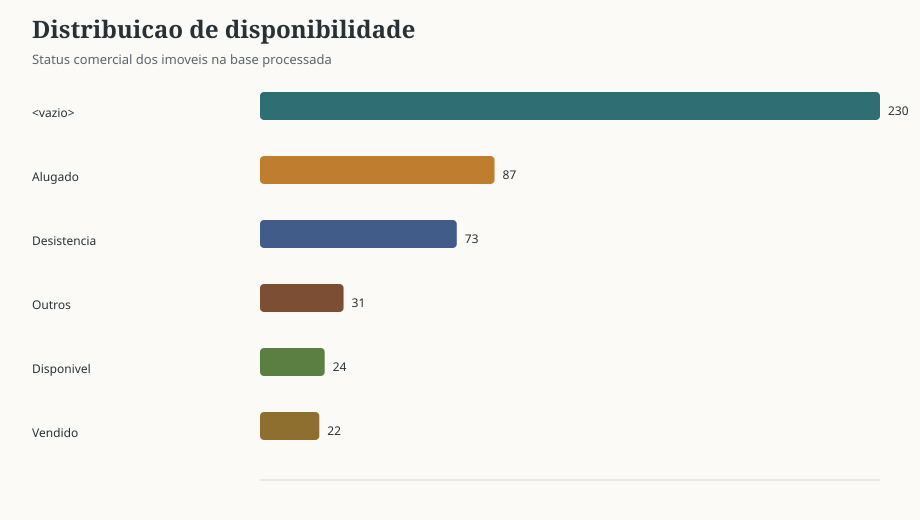

In [16]:
show_bar_chart(
    "Distribuicao de disponibilidade",
    disponibilidade.most_common(),
    subtitle="Status comercial dos imoveis na base processada",
)

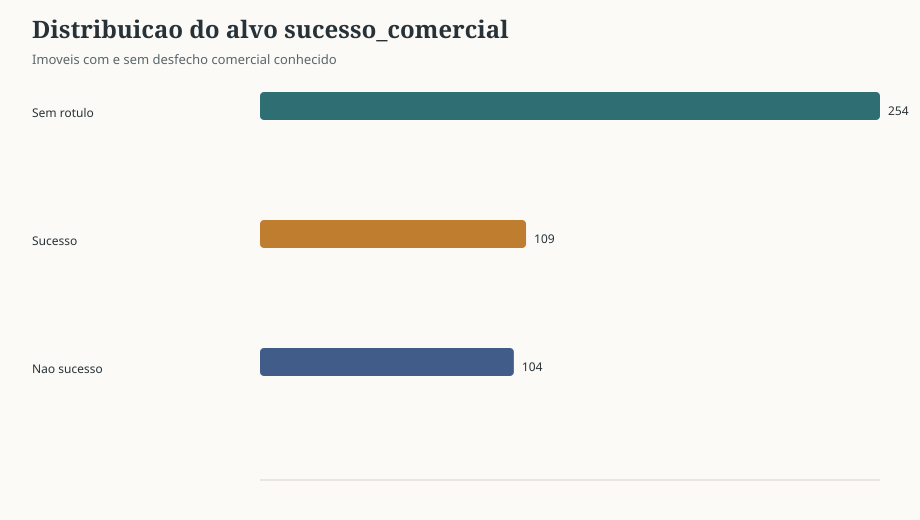

In [17]:
show_bar_chart(
    "Distribuicao do alvo sucesso_comercial",
    list(target.items()),
    subtitle="Imoveis com e sem desfecho comercial conhecido",
)

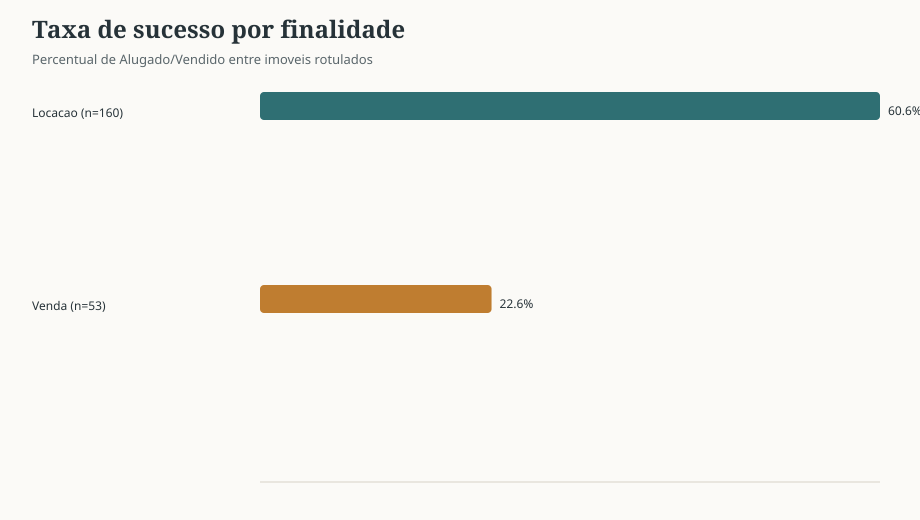

In [18]:
show_bar_chart(
    "Taxa de sucesso por finalidade",
    [(f"{label} (n={n})", rate) for label, rate, n in finalidade_rate],
    subtitle="Percentual de Alugado/Vendido entre imoveis rotulados",
    value_suffix="%",
)

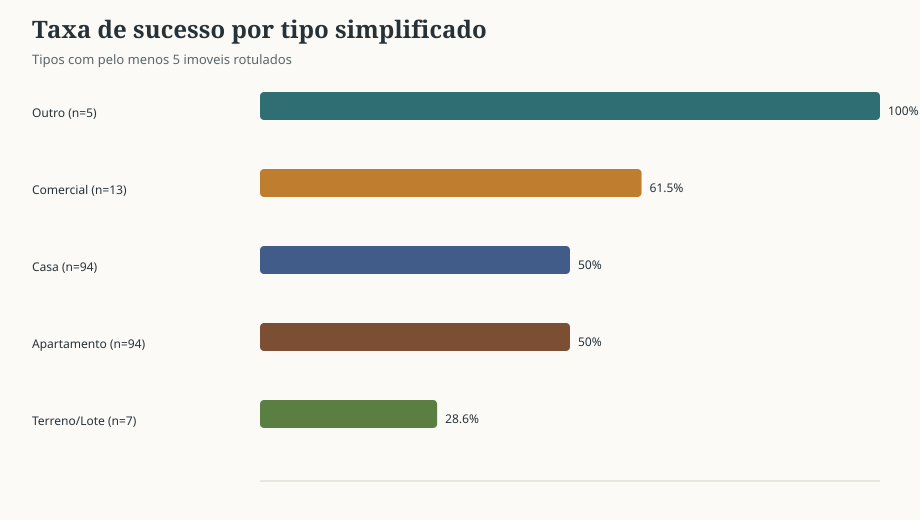

In [19]:
show_bar_chart(
    "Taxa de sucesso por tipo simplificado",
    [(f"{label} (n={n})", rate) for label, rate, n in tipo_rate],
    subtitle="Tipos com pelo menos 5 imoveis rotulados",
    value_suffix="%",
)

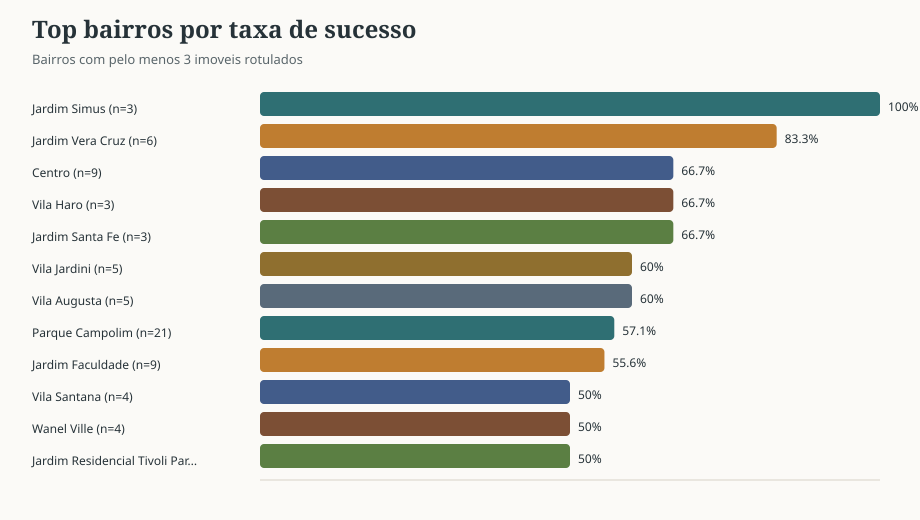

In [20]:
show_bar_chart(
    "Top bairros por taxa de sucesso",
    [(f"{label} (n={n})", rate) for label, rate, n in bairro_rate],
    subtitle="Bairros com pelo menos 3 imoveis rotulados",
    value_suffix="%",
)

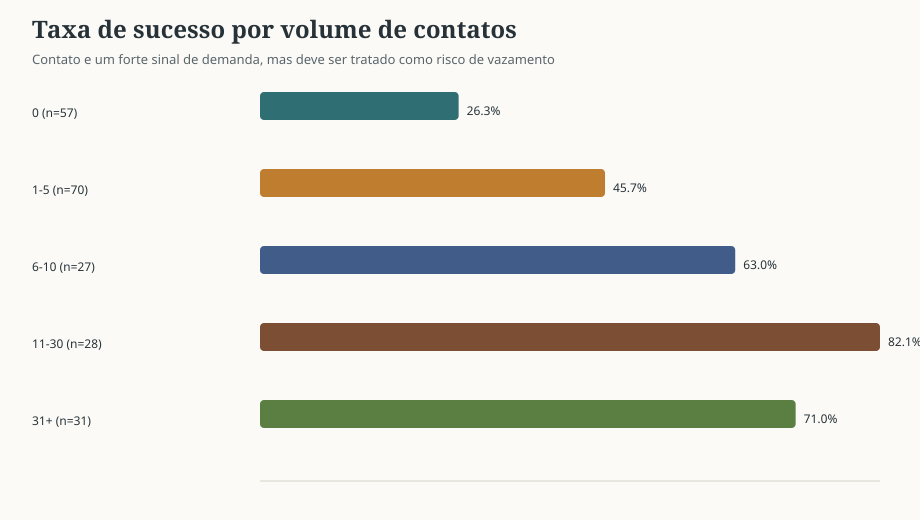

In [21]:
show_bar_chart(
    "Taxa de sucesso por volume de contatos",
    [(f"{label} (n={n})", rate) for label, rate, n in contato_bins],
    subtitle="Contato e um forte sinal de demanda, mas deve ser tratado como risco de vazamento",
    value_suffix="%",
)

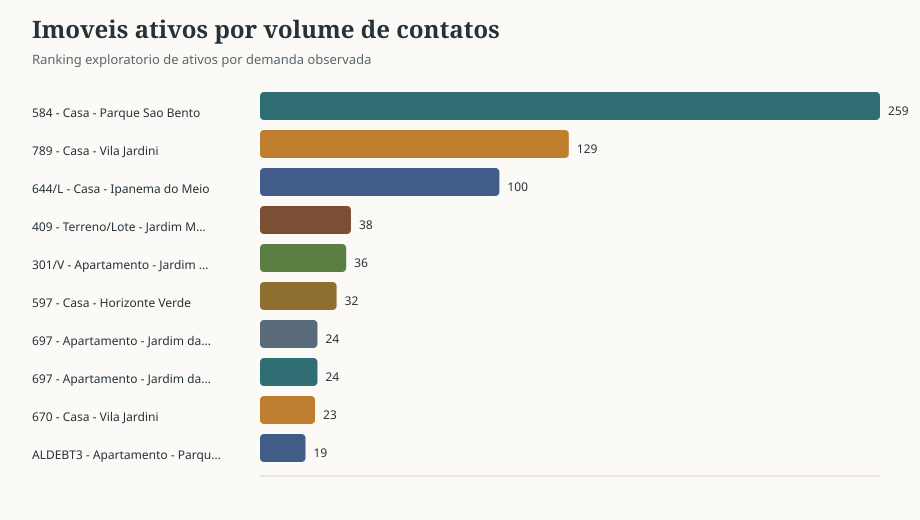

In [22]:
show_bar_chart(
    "Imoveis ativos por volume de contatos",
    [
        (
            f"{row.get('referencia_id')} - {row.get('tipo_simplificado')} - {row.get('bairro')}",
            to_int(row.get("total_contatos", "")),
        )
        for row in top_active[:10]
    ],
    subtitle="Ranking exploratorio de ativos por demanda observada",
)

## 8. Interpretação da análise inicial

Indicadores, interpretações dos gráficos, ranking e limitações são apresentados abaixo.

In [23]:
success_avg = avg_contacts.get("Sucesso", 0)
nonsuccess_avg = avg_contacts.get("Nao sucesso", 0)
active_with_contacts = sum(1 for row in scoring if to_int(row.get("total_contatos", "")) > 0)

insights = [
    f"A base processada possui {len(rows)} imoveis; {len(labeled)} possuem desfecho conhecido e {len(scoring)} permanecem sem rotulo.",
    f"Distribuicao dos desfechos conhecidos: {target.get('Sucesso', 0)} sucessos contra {target.get('Nao sucesso', 0)} nao sucessos.",
    f"Imoveis com sucesso comercial possuem media de {success_avg:.1f} contatos, contra {nonsuccess_avg:.1f} em nao sucessos; contato e sinal forte de demanda.",
    f"Ha {active_with_contacts} imoveis ativos/sem desfecho com pelo menos um contato, bons candidatos para priorizacao operacional imediata.",
    "Sem a data de fechamento, não é possível distinguir contatos anteriores e posteriores ao desfecho comercial.",
    "Referencias alfanumericas e duplicadas justificam manter `referencia_id` textual e validar se a chave final deve incluir `finalidade`.",
]

report = [
    "# EDA - Sucesso Comercial de Imoveis",
    "",
    "Fonte: base analítica preparada em memória a partir dos três CSVs de entrada.",
    "",
    "## Resumo Executivo",
    "",
    *[f"- {item}" for item in insights],
    "",
    "## Indicadores Gerais",
    "",
    format_table(
        ["Indicador", "Valor"],
        [
            ["Imoveis na base processada", len(rows)],
            ["Imoveis com desfecho conhecido", len(labeled)],
            ["Imoveis sem desfecho conhecido", len(scoring)],
            ["Sucessos comerciais", target.get("Sucesso", 0)],
            ["Nao sucessos", target.get("Nao sucesso", 0)],
            ["Imoveis sem desfecho com contatos", active_with_contacts],
            ["Media de contatos em sucessos", f"{success_avg:.1f}"],
            ["Media de contatos em nao sucessos", f"{nonsuccess_avg:.1f}"],
        ],
    ),
    "",
    "## Graficos Interpretados",
    "",
    "### 1. Distribuicao de disponibilidade",
    "",
    "",
    "Interpretação: a base mistura imóveis encerrados, desistências/outros e uma quantidade relevante de imóveis sem desfecho final. Esses imóveis sem rótulo são justamente o público do ranking.",
    "",
    "### 2. Distribuicao de sucesso comercial",
    "",
    "",
    "Interpretação: compare os volumes de sucesso e não sucesso apenas entre os imóveis com desfecho conhecido.",
    "",
    "### 3. Taxa de sucesso por finalidade",
    "",
    "",
    "Interpretação: finalidade é uma variável central porque venda e locação têm ciclos comerciais diferentes. As taxas devem ser comparadas separadamente por finalidade.",
    "",
    "### 4. Taxa de sucesso por tipo de imóvel",
    "",
    "",
    "Interpretação: tipo simplificado facilita a comparação entre grupos de imóveis, separando grupos como Casa, Apartamento, Comercial e Terreno/Lote.",
    "",
    "### 5. Taxa de sucesso por bairro",
    "",
    "",
    "Interpretação: bairro tem potencial explicativo, mas precisa de cuidado com baixo volume. Categorias com poucos registros não sustentam conclusões gerais.",
    "",
    "### 6. Taxa de sucesso por faixa de contatos",
    "",
    "",
    "Interpretação: o aumento de contatos se relaciona com sucesso comercial, mas esse é também o principal risco de vazamento temporal porque não há data de fechamento.",
    "",
    "### 7. Ranking exploratorio de ativos por contatos",
    "",
    "",
    "Interpretação: o volume de contatos identifica imóveis com maior demanda observada, mas não estima a probabilidade de fechamento.",
    "",
    "## Ranking Exploratorio de Imoveis Ativos",
    "",
    format_table(
        ["Referencia", "Finalidade", "Tipo", "Bairro", "Valor", "Contatos"],
        [
            [
                row.get("referencia_id"),
                row.get("finalidade"),
                row.get("tipo_simplificado"),
                row.get("bairro"),
                row.get("valor_num") or "-",
                to_int(row.get("total_contatos", "")),
            ]
            for row in top_active[:15]
        ],
    ),
    "",
    "## Problemas e Riscos dos Dados",
    "",
    "- Existem referências duplicadas; a chave adotada nesta análise é `referencia_id`, e duplicidades por finalidade devem ser acompanhadas como limitação.",
    "- Existem referências alfanuméricas; converter referência para número perde informação.",
    "- Parte dos contatos não possui código de imóvel e não entra na base analítica por imóvel.",
    "- Sem data de fechamento, contatos podem representar informação posterior ao desfecho.",
    "- Algumas categorias têm baixo volume por bairro/tipo, exigindo cuidado na interpretação.",
    "- Os CSVs são lidos localmente; esta análise não envia dados a serviços externos.",
    "",
    "## Proximas Acoes",
    "",
    "- Validar a cobertura e as regras de preparação dos CSVs de entrada.",
    "- Validar a chave analítica final com o grupo.",
    "- Investigar a cobertura dos contatos e a disponibilidade de datas de fechamento.",
    "- Confirmar com a empresa as interpretações dos padrões observados.",
    "",
]

display(Markdown("\n".join(report)))

# EDA - Sucesso Comercial de Imoveis

Fonte: base analítica preparada em memória a partir dos três CSVs de entrada.

## Resumo Executivo

- A base processada possui 467 imoveis; 213 possuem desfecho conhecido e 254 permanecem sem rotulo.
- Distribuicao dos desfechos conhecidos: 109 sucessos contra 104 nao sucessos.
- Imoveis com sucesso comercial possuem media de 20.1 contatos, contra 6.2 em nao sucessos; contato e sinal forte de demanda.
- Ha 134 imoveis ativos/sem desfecho com pelo menos um contato, bons candidatos para priorizacao operacional imediata.
- Sem a data de fechamento, não é possível distinguir contatos anteriores e posteriores ao desfecho comercial.
- Referencias alfanumericas e duplicadas justificam manter `referencia_id` textual e validar se a chave final deve incluir `finalidade`.

## Indicadores Gerais

| Indicador | Valor |
| --- | --- |
| Imoveis na base processada | 467 |
| Imoveis com desfecho conhecido | 213 |
| Imoveis sem desfecho conhecido | 254 |
| Sucessos comerciais | 109 |
| Nao sucessos | 104 |
| Imoveis sem desfecho com contatos | 134 |
| Media de contatos em sucessos | 20.1 |
| Media de contatos em nao sucessos | 6.2 |

## Graficos Interpretados

### 1. Distribuicao de disponibilidade


Interpretação: a base mistura imóveis encerrados, desistências/outros e uma quantidade relevante de imóveis sem desfecho final. Esses imóveis sem rótulo são justamente o público do ranking.

### 2. Distribuicao de sucesso comercial


Interpretação: compare os volumes de sucesso e não sucesso apenas entre os imóveis com desfecho conhecido.

### 3. Taxa de sucesso por finalidade


Interpretação: finalidade é uma variável central porque venda e locação têm ciclos comerciais diferentes. As taxas devem ser comparadas separadamente por finalidade.

### 4. Taxa de sucesso por tipo de imóvel


Interpretação: tipo simplificado facilita a comparação entre grupos de imóveis, separando grupos como Casa, Apartamento, Comercial e Terreno/Lote.

### 5. Taxa de sucesso por bairro


Interpretação: bairro tem potencial explicativo, mas precisa de cuidado com baixo volume. Categorias com poucos registros não sustentam conclusões gerais.

### 6. Taxa de sucesso por faixa de contatos


Interpretação: o aumento de contatos se relaciona com sucesso comercial, mas esse é também o principal risco de vazamento temporal porque não há data de fechamento.

### 7. Ranking exploratorio de ativos por contatos


Interpretação: o volume de contatos identifica imóveis com maior demanda observada, mas não estima a probabilidade de fechamento.

## Ranking Exploratorio de Imoveis Ativos

| Referencia | Finalidade | Tipo | Bairro | Valor | Contatos |
| --- | --- | --- | --- | --- | --- |
| 584 | Locação | Casa | Parque São Bento | 1500.0 | 259 |
| 789 | Locação | Casa | Vila Jardini | 990.0 | 129 |
| 644/L | Locação | Casa | Ipanema do Meio | 1200.0 | 100 |
| 409 | Venda | Terreno/Lote | Jardim Morumbi | 139900.0 | 38 |
| 301/V | Venda | Apartamento | Jardim Antônio Cassillo | 270000.0 | 36 |
| 597 | Venda | Casa | Horizonte Verde | 190000.0 | 32 |
| 697 | Locação | Apartamento | Jardim das Estrelas | 2000.0 | 24 |
| 697 | Venda | Apartamento | Jardim das Estrelas | 350000.0 | 24 |
| 670 | Locação | Casa | Vila Jardini | 1150.0 | 23 |
| ALDEBT3 | Venda | Apartamento | Parque Campolim | 2150000.0 | 19 |
| J792 | Locação | Casa | Jardim Zulmira | 2000.0 | 16 |
| J792 | Venda | Casa | Jardim Zulmira | 330000.0 | 16 |
| 785 | Locação | Apartamento | Jardim Piazza di Roma | 1200.0 | 14 |
| 343 | Venda | Terreno/Lote | Jardim Novo Horizonte | 230000.0 | 14 |
| 336 | Venda | Casa | Vila Gabriel | 550000.0 | 13 |

## Problemas e Riscos dos Dados

- Existem referências duplicadas; a chave adotada nesta análise é `referencia_id`, e duplicidades por finalidade devem ser acompanhadas como limitação.
- Existem referências alfanuméricas; converter referência para número perde informação.
- Parte dos contatos não possui código de imóvel e não entra na base analítica por imóvel.
- Sem data de fechamento, contatos podem representar informação posterior ao desfecho.
- Algumas categorias têm baixo volume por bairro/tipo, exigindo cuidado na interpretação.
- Os CSVs são lidos localmente; esta análise não envia dados a serviços externos.

## Proximas Acoes

- Validar a cobertura e as regras de preparação dos CSVs de entrada.
- Validar a chave analítica final com o grupo.
- Investigar a cobertura dos contatos e a disponibilidade de datas de fechamento.
- Confirmar com a empresa as interpretações dos padrões observados.


## 9. Estatísticas descritivas e qualidade

**Perguntas:** quais variáveis têm informação suficiente? Há valores ausentes, referências repetidas ou preços extremos?

Valores monetários são descritos por finalidade, pois venda e locação têm escalas diferentes. Um zero em dormitórios, suítes, banheiros ou garagens também pode significar que a informação não foi encontrada no texto: a regra original não distingue ausência de zero real. Ausências não são imputadas nesta EDA.

In [24]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
eda_tables = {}

def table_markdown(frame):
    data = frame.copy().astype(object).where(frame.notna(), "—")
    def safe(value):
        if isinstance(value, float):
            return f"{value:.3f}"
        return str(value).replace("|", " / ").replace("\n", " ")
    return format_table([safe(c) for c in data.columns], [[safe(v) for v in row] for row in data.itertuples(index=False, name=None)])

def show_table(name, frame):
    eda_tables[name] = frame
    display(Markdown(table_markdown(frame)))

def show_figure(fig):
    # Normaliza títulos, legendas, anotações e rótulos sem alterar os dados.
    for text in fig.findobj(match=Text):
        text.set_text(chart_text(text.get_text()))
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            formatter = axis.get_major_formatter()
            axis.set_major_formatter(FuncFormatter(
                lambda value, position, original=formatter: chart_text(original(value, position))
            ))
    fig.tight_layout()
    # A imagem é produzida em memória e incorporada à saída da célula.
    with BytesIO() as buffer:
        fig.savefig(buffer, format="png", bbox_inches="tight")
        display(Image(data=buffer.getvalue()))
    plt.close(fig)


df = pd.DataFrame(dataset).replace("", np.nan)
for column in ("referencia_id", "chave_analitica"):
    df[column] = df[column].astype("string")
num_cols = ["valor_num", "valor_iptu_num", "valor_condominio_num", "valor_taxas_num", "valor_m2_num",
            "dormitorios", "suites", "banheiros", "garagens", "total_contatos", "qtd_nomes_contato_unicos",
            "dias_entre_primeiro_ultimo_contato", "qtd_cadastros_ref", "idade_cadastro_dias"]
for column in num_cols + ["sucesso_comercial"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
labeled_df = df[df.sucesso_comercial.isin([0, 1])].copy()
quality = pd.DataFrame({"variavel": df.columns, "ausentes": df.isna().sum().values,
                        "ausentes_pct": (df.isna().mean()*100).values,
                        "valores_distintos": df.nunique().values})
show_table("qualidade_variaveis", quality.sort_values("ausentes_pct", ascending=False))
descriptive = df[num_cols].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T.reset_index(names="variavel")
descriptive["assimetria"] = df[num_cols].skew().values
show_table("estatisticas_descritivas", descriptive)
price_summary = df.groupby("finalidade", dropna=False)["valor_num"].describe().reset_index()
show_table("precos_por_finalidade", price_summary)
duplicate_rows = int((df.referencia_id.notna() & df.referencia_id.duplicated(keep=False)).sum())
duplicate_refs = int(df.loc[(df.referencia_id.notna() & df.referencia_id.duplicated(keep=False)), "referencia_id"].nunique())
print(f"{len(df)} linhas; {duplicate_rows} linhas em {duplicate_refs} referências repetidas.")

467 linhas; 46 linhas em 23 referências repetidas.


| variavel | ausentes | ausentes_pct | valores_distintos |
| --- | --- | --- | --- |
| captacao_principal | 467 | 100.000 | 0 |
| valor_taxas_num | 465 | 99.572 | 2 |
| zona | 450 | 96.360 | 6 |
| idade_cadastro_dias | 435 | 93.148 | 17 |
| cliente_desde_mais_antigo | 435 | 93.148 | 17 |
| regiao | 416 | 89.079 | 12 |
| valor_m2_num | 279 | 59.743 | 179 |
| sucesso_comercial | 254 | 54.390 | 2 |
| disponibilidade | 230 | 49.251 | 5 |
| valor_condominio_num | 205 | 43.897 | 159 |
| condominio | 195 | 41.756 | 187 |
| ultima_data_contato | 177 | 37.901 | 270 |
| hora_modal_contato | 177 | 37.901 | 23 |
| dia_semana_modal_contato | 177 | 37.901 | 7 |
| primeira_data_contato | 177 | 37.901 | 270 |
| dias_entre_primeiro_ultimo_contato | 177 | 37.901 | 146 |
| valor_iptu_num | 88 | 18.844 | 224 |
| referencia_id | 2 | 0.428 | 442 |
| chave_analitica | 2 | 0.428 | 442 |
| valor_num | 1 | 0.214 | 247 |
| exibir | 0 | 0.000 | 2 |
| cidade | 0 | 0.000 | 12 |
| bairro | 0 | 0.000 | 165 |
| tipo | 0 | 0.000 | 28 |
| tipo_simplificado | 0 | 0.000 | 5 |
| finalidade | 0 | 0.000 | 2 |
| grupo_disponibilidade | 0 | 0.000 | 3 |
| dormitorios | 0 | 0.000 | 9 |
| cep | 0 | 0.000 | 289 |
| total_contatos | 0 | 0.000 | 52 |
| qtd_nomes_contato_unicos | 0 | 0.000 | 51 |
| garagens | 0 | 0.000 | 12 |
| atualizado_em | 0 | 0.000 | 410 |
| banheiros | 0 | 0.000 | 10 |
| suites | 0 | 0.000 | 6 |
| qtd_origem_chaves_na_mao | 0 | 0.000 | 4 |
| qtd_origem_olx | 0 | 0.000 | 50 |
| qtd_contatos_tipo_whatsapp | 0 | 0.000 | 47 |
| qtd_origem_site | 0 | 0.000 | 8 |
| qtd_origem_buskaza | 0 | 0.000 | 2 |
| qtd_contatos_tipo_outros_meios | 0 | 0.000 | 27 |
| tem_perfil_proprietario | 0 | 0.000 | 2 |
| qtd_cadastros_ref | 0 | 0.000 | 4 |
| tem_cadastro_relacionado | 0 | 0.000 | 2 |
| tem_perfil_cliente | 0 | 0.000 | 2 |

| variavel | count | mean | std | min | 1% | 25% | 50% | 75% | 95% | 99% | max | assimetria |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| valor_num | 466.000 | 591436.785 | 964793.115 | 600.000 | 1000.000 | 3000.000 | 220000.000 | 718750.000 | 2660000.000 | 4005000.000 | 6900000.000 | 2.610 |
| valor_iptu_num | 379.000 | 504.536 | 1979.158 | 17.000 | 24.340 | 65.000 | 120.740 | 400.000 | 1819.241 | 4372.000 | 36000.000 | 15.551 |
| valor_condominio_num | 262.000 | 761.824 | 704.220 | 99.000 | 150.000 | 360.000 | 598.500 | 877.500 | 1900.000 | 4140.610 | 5989.000 | 3.860 |
| valor_taxas_num | 2.000 | 147.500 | 67.175 | 100.000 | 100.950 | 123.750 | 147.500 | 171.250 | 190.250 | 194.050 | 195.000 | — |
| valor_m2_num | 188.000 | 56880.021 | 191602.971 | 2.000 | 2.870 | 2878.750 | 4979.500 | 9685.000 | 397500.000 | 970650.000 | 1425000.000 | 4.589 |
| dormitorios | 467.000 | 2.321 | 1.328 | 0.000 | 0.000 | 2.000 | 2.000 | 3.000 | 4.000 | 5.340 | 9.000 | 0.113 |
| suites | 467.000 | 1.092 | 1.280 | 0.000 | 0.000 | 0.000 | 1.000 | 2.000 | 4.000 | 4.000 | 5.000 | 1.043 |
| banheiros | 467.000 | 2.364 | 1.869 | 0.000 | 0.000 | 1.000 | 2.000 | 3.500 | 6.000 | 7.000 | 11.000 | 0.925 |
| garagens | 467.000 | 1.921 | 2.340 | 0.000 | 0.000 | 0.000 | 2.000 | 3.000 | 6.000 | 8.680 | 20.000 | 2.537 |
| total_contatos | 467.000 | 8.488 | 24.347 | 0.000 | 0.000 | 0.000 | 1.000 | 6.000 | 38.000 | 130.020 | 259.000 | 6.324 |
| qtd_nomes_contato_unicos | 467.000 | 7.422 | 20.856 | 0.000 | 0.000 | 0.000 | 1.000 | 5.000 | 34.000 | 111.040 | 231.000 | 6.306 |
| dias_entre_primeiro_ultimo_contato | 290.000 | 117.910 | 171.108 | 0.000 | 0.000 | 0.000 | 45.000 | 143.250 | 544.000 | 647.430 | 682.000 | 1.741 |
| qtd_cadastros_ref | 467.000 | 0.075 | 0.294 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 1.000 | 1.000 | 3.000 | 4.709 |
| idade_cadastro_dias | 32.000 | 721.625 | 281.583 | 162.000 | 175.950 | 478.750 | 819.500 | 968.000 | 987.350 | 989.690 | 990.000 | -0.638 |

| finalidade | count | mean | std | min | 25% | 50% | 75% | max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Locação | 216.000 | 5378.903 | 8914.697 | 600.000 | 1500.000 | 2775.000 | 6500.000 | 110000.000 |
| Venda | 250.000 | 1097790.796 | 1087589.914 | 65000.000 | 362500.000 | 687450.000 | 1499750.000 | 6900000.000 |

## 10. Distribuições e outliers

Histogramas em escala `log1p` evidenciam assimetria sem excluir valores. Os boxplots separam as finalidades. O critério exploratório de outlier é 1,5 × IQR, calculado por finalidade e tipo, apenas em grupos com ao menos oito preços e IQR positivo. Grupos menores ou sem dispersão ficam sem avaliação. Nenhuma linha é removida: preços altos podem ser legítimos; qualquer corte deve ser validado com a empresa antes de qualquer exclusão.

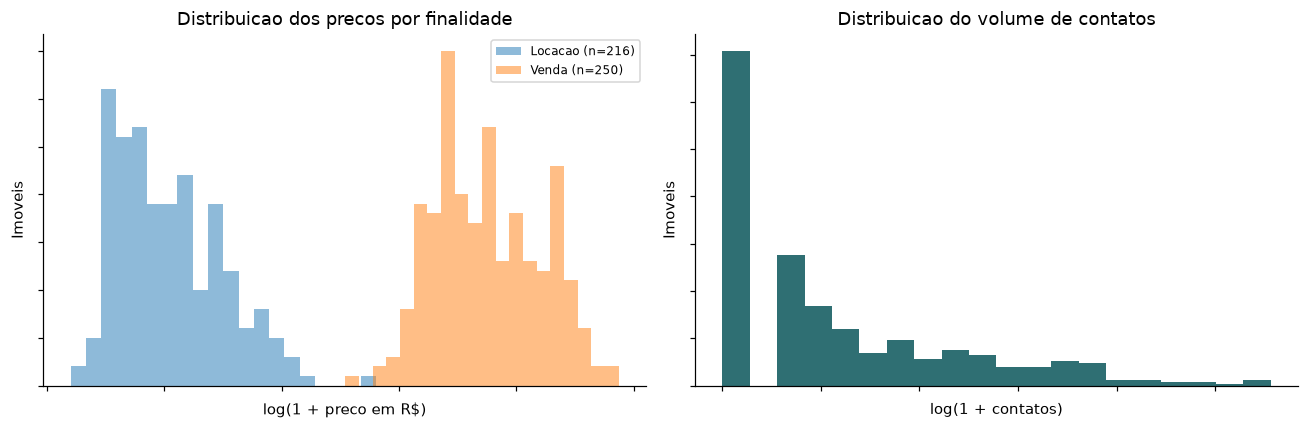

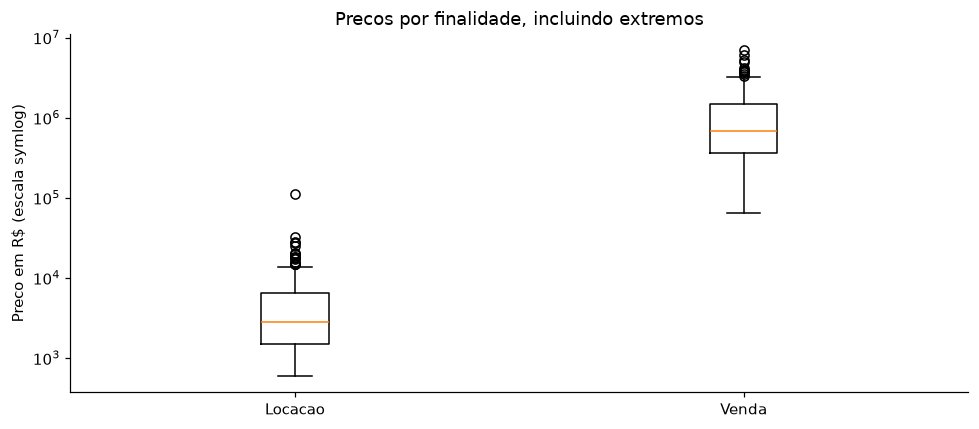

| finalidade | tipo | n_precos | avaliado | limite_inferior | limite_superior | outliers |
| --- | --- | --- | --- | --- | --- | --- |
| Locação | Apartamento | 93 | True | -1325.000 | 5915.000 | 11.000 |
| Locação | Casa | 93 | True | -7000.000 | 16200.000 | 5.000 |
| Locação | Comercial | 20 | True | -8281.250 | 17968.750 | 2.000 |
| Locação | Outro | 8 | True | -17845.750 | 45276.250 | 0.000 |
| Locação | Terreno/Lote | 2 | False | — | — | — |
| Venda | Apartamento | 64 | True | -957500.000 | 2354500.000 | 3.000 |
| Venda | Casa | 145 | True | -1850000.000 | 4230000.000 | 4.000 |
| Venda | Comercial | 6 | False | — | — | — |
| Venda | Outro | 5 | False | — | — | — |
| Venda | Terreno/Lote | 30 | True | -381562.500 | 1279937.500 | 0.000 |

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for purpose, group in df.groupby("finalidade", dropna=False):
    values = group.valor_num.dropna()
    values = values[values >= 0]
    axes[0].hist(np.log1p(values), bins=20, alpha=.5, label=f"{purpose} (n={len(values)})")
axes[0].set(title="Distribuição dos preços por finalidade", xlabel="log(1 + preço em R$)", ylabel="Imóveis")
axes[0].legend(fontsize=8)
axes[1].hist(np.log1p(df.total_contatos.dropna()), bins=20, color="#2f6f73")
axes[1].set(title="Distribuição do volume de contatos", xlabel="log(1 + contatos)", ylabel="Imóveis")
show_figure(fig)

groups = [(str(k), g.valor_num.dropna()) for k,g in df.groupby("finalidade", dropna=False) if g.valor_num.notna().any()]
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([g for _,g in groups], tick_labels=[k for k,_ in groups])
ax.set_yscale("symlog", linthresh=1)
ax.set(title="Preços por finalidade, incluindo extremos", ylabel="Preço em R$ (escala symlog)")
show_figure(fig)

outlier_parts = []
for (purpose, kind), group in df.groupby(["finalidade", "tipo_simplificado"], dropna=False):
    valid = group.valor_num.dropna()
    q1, q3 = valid.quantile([.25,.75]) if len(valid) else (np.nan,np.nan)
    iqr = q3-q1
    eligible = len(valid) >= 8 and iqr > 0
    low, high = q1-1.5*iqr, q3+1.5*iqr
    flags = ((valid < low) | (valid > high)) if eligible else pd.Series(dtype=bool)
    outlier_parts.append({"finalidade": purpose, "tipo": kind, "n_precos":len(valid),
                          "avaliado":eligible, "limite_inferior":low if eligible else np.nan,
                          "limite_superior":high if eligible else np.nan,
                          "outliers":int(flags.sum()) if eligible else np.nan})
outlier_summary = pd.DataFrame(outlier_parts)
show_table("outliers_por_segmento", outlier_summary)

## 11. Correlações e relação com o alvo

Pearson mede associação linear; Spearman mede associação monotônica por postos e é menos sensível à escala dos preços. Correlações com o alvo usam **apenas imóveis rotulados** e ao menos 20 pares válidos. A matriz usa exclusão de ausências por par; a tabela informa o `n` de cada associação com o alvo. Não são efeitos causais, testes confirmatórios nem medidas de influência causal. Contatos são analisados como possível vazamento temporal; `disponibilidade` e `grupo_disponibilidade` são excluídos porque definem diretamente o alvo.

| variavel | valor_num | dormitorios | suites | banheiros | garagens | total_contatos | qtd_nomes_contato_unicos | qtd_cadastros_ref | idade_cadastro_dias | sucesso_comercial |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| valor_num | 1.000 | 0.324 | 0.379 | 0.348 | 0.394 | -0.416 | -0.416 | 0.011 | — | -0.287 |
| dormitorios | 0.324 | 1.000 | 0.636 | 0.749 | 0.616 | -0.052 | -0.057 | 0.021 | — | -0.037 |
| suites | 0.379 | 0.636 | 1.000 | 0.800 | 0.684 | -0.197 | -0.199 | -0.056 | — | -0.073 |
| banheiros | 0.348 | 0.749 | 0.800 | 1.000 | 0.710 | -0.060 | -0.062 | -0.028 | — | -0.016 |
| garagens | 0.394 | 0.616 | 0.684 | 0.710 | 1.000 | -0.106 | -0.109 | -0.041 | — | -0.030 |
| total_contatos | -0.416 | -0.052 | -0.197 | -0.060 | -0.106 | 1.000 | 0.998 | 0.062 | — | 0.369 |
| qtd_nomes_contato_unicos | -0.416 | -0.057 | -0.199 | -0.062 | -0.109 | 0.998 | 1.000 | 0.064 | — | 0.362 |
| qtd_cadastros_ref | 0.011 | 0.021 | -0.056 | -0.028 | -0.041 | 0.062 | 0.064 | 1.000 | — | -0.047 |
| idade_cadastro_dias | — | — | — | — | — | — | — | — | — | — |
| sucesso_comercial | -0.287 | -0.037 | -0.073 | -0.016 | -0.030 | 0.369 | 0.362 | -0.047 | — | 1.000 |

| variavel | valor_num | dormitorios | suites | banheiros | garagens | total_contatos | qtd_nomes_contato_unicos | qtd_cadastros_ref | idade_cadastro_dias | sucesso_comercial |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| valor_num | 1.000 | 0.236 | 0.308 | 0.321 | 0.346 | -0.135 | -0.139 | -0.032 | — | -0.170 |
| dormitorios | 0.236 | 1.000 | 0.583 | 0.701 | 0.531 | -0.102 | -0.099 | 0.044 | — | -0.045 |
| suites | 0.308 | 0.583 | 1.000 | 0.858 | 0.670 | -0.198 | -0.204 | 0.017 | — | -0.054 |
| banheiros | 0.321 | 0.701 | 0.858 | 1.000 | 0.727 | -0.148 | -0.152 | -0.000 | — | -0.043 |
| garagens | 0.346 | 0.531 | 0.670 | 0.727 | 1.000 | -0.179 | -0.182 | -0.026 | — | -0.047 |
| total_contatos | -0.135 | -0.102 | -0.198 | -0.148 | -0.179 | 1.000 | 0.998 | 0.010 | — | 0.247 |
| qtd_nomes_contato_unicos | -0.139 | -0.099 | -0.204 | -0.152 | -0.182 | 0.998 | 1.000 | 0.010 | — | 0.250 |
| qtd_cadastros_ref | -0.032 | 0.044 | 0.017 | -0.000 | -0.026 | 0.010 | 0.010 | 1.000 | — | -0.060 |
| idade_cadastro_dias | — | — | — | — | — | — | — | — | — | — |
| sucesso_comercial | -0.170 | -0.045 | -0.054 | -0.043 | -0.047 | 0.247 | 0.250 | -0.060 | — | 1.000 |

| variavel | n_pares | spearman | pearson |
| --- | --- | --- | --- |
| total_contatos | 213 | 0.369 | 0.247 |
| qtd_nomes_contato_unicos | 213 | 0.362 | 0.250 |
| valor_num | 213 | -0.287 | -0.170 |
| suites | 213 | -0.073 | -0.054 |
| qtd_cadastros_ref | 213 | -0.047 | -0.060 |
| dormitorios | 213 | -0.037 | -0.045 |
| garagens | 213 | -0.030 | -0.047 |
| banheiros | 213 | -0.016 | -0.043 |
| idade_cadastro_dias | 12 | — | — |

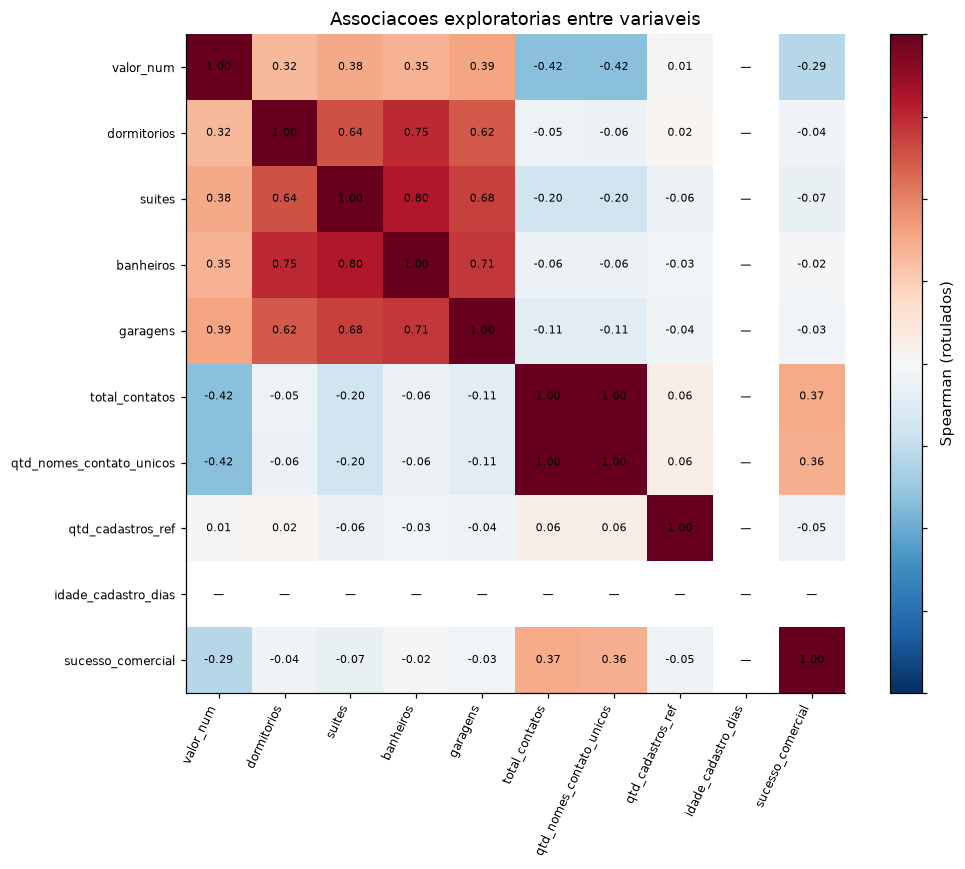

In [26]:
corr_cols = ["valor_num", "dormitorios", "suites", "banheiros", "garagens", "total_contatos",
             "qtd_nomes_contato_unicos", "qtd_cadastros_ref", "idade_cadastro_dias", "sucesso_comercial"]
spearman = labeled_df[corr_cols].corr(method="spearman", min_periods=20)
pearson = labeled_df[corr_cols].corr(method="pearson", min_periods=20)
show_table("correlacao_spearman", spearman.reset_index(names="variavel"))
show_table("correlacao_pearson", pearson.reset_index(names="variavel"))
association = pd.DataFrame({"variavel":corr_cols[:-1],
    "n_pares":[int(labeled_df[[c,"sucesso_comercial"]].dropna().shape[0]) for c in corr_cols[:-1]],
    "spearman":[spearman.loc[c,"sucesso_comercial"] for c in corr_cols[:-1]],
    "pearson":[pearson.loc[c,"sucesso_comercial"] for c in corr_cols[:-1]]})
association = association.sort_values("spearman", key=lambda x:x.abs(), ascending=False)
show_table("associacao_com_alvo", association)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(spearman.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=65, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_cols)), corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        value = spearman.iloc[i,j]
        ax.text(j,i, f"{value:.2f}" if pd.notna(value) else "—", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Spearman (rotulados)")
ax.set_title("Associações exploratórias entre variáveis")
show_figure(fig)

## 12. Segmentações com tamanho da amostra

Taxas por finalidade, tipo, bairro, cidade, zona e região incluem denominadores e intervalos de Wilson de 95%. Esses intervalos são referências descritivas: referências duplicadas e seleção da amostra violam a hipótese de observações independentes. Grupos com menos de dez rotulados são sinalizados; diferenças não comprovam significância ou causalidade. Venda e locação também são separadas na análise de preços.

| variavel | segmento | n | sucessos | taxa_pct | ic95_inferior_pct | ic95_superior_pct | baixo_volume |
| --- | --- | --- | --- | --- | --- | --- | --- |
| finalidade | Locação | 160 | 97 | 60.625 | 52.890 | 67.861 | False |
| finalidade | Venda | 53 | 12 | 22.642 | 13.454 | 35.527 | False |
| tipo_simplificado | Apartamento | 94 | 47 | 50.000 | 40.092 | 59.908 | False |
| tipo_simplificado | Casa | 94 | 47 | 50.000 | 40.092 | 59.908 | False |
| tipo_simplificado | Comercial | 13 | 8 | 61.538 | 35.522 | 82.291 | False |
| tipo_simplificado | Outro | 5 | 5 | 100.000 | 56.551 | 100.000 | True |
| tipo_simplificado | Terreno/Lote | 7 | 2 | 28.571 | 8.222 | 64.107 | True |
| bairro | Alphaville Itu | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Alphaville Nova Esplanada | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Alphaville Nova Esplanada 3 | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Além Ponte | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Ana Maria | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Aparecidinha | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Bairro da Vossoroca | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Boa Vista | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Caguassu | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Centro | 9 | 6 | 66.667 | 35.420 | 87.942 | True |
| bairro | Chácaras Residenciais Santa Maria | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Cyrela Landscape Esplanada | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Elton Ville | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Granja Olga I | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Horto Florestal | 3 | 0 | 0.000 | 0.000 | 56.151 | True |
| bairro | Ibiti Royal Park | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Ipanema do Meio | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Iporanga | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Itapeva | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Abaeté | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Americado | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim América | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Jardim Ana Maria | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Bertanha | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Jardim Califórnia | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Emília | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Jardim Faculdade | 9 | 5 | 55.556 | 26.665 | 81.122 | True |
| bairro | Jardim Golden Park Residence | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Gonçalves | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Jardim Guadalajara | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Guarujá | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Jardim Gutierres | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Ibiti do Paço | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Isaura | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Judith | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Jardim Karolyne | 3 | 0 | 0.000 | 0.000 | 56.151 | True |
| bairro | Jardim Maria Antônia Prado | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Maria do Carmo | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Morumbi | 2 | 0 | 0.000 | 0.000 | 65.763 | True |
| bairro | Jardim Nova Manchester | 4 | 1 | 25.000 | 4.559 | 69.936 | True |
| bairro | Jardim Novo Mundo | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Pagliato | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Jardim Paulista | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Paulistano | 5 | 2 | 40.000 | 11.762 | 76.928 | True |
| bairro | Jardim Piratininga | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Portal da Colina | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Prestes de Barros | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Refúgio | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Jardim Residencial Chácara Ondina | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Residencial Tivoli Park | 4 | 2 | 50.000 | 15.004 | 84.996 | True |
| bairro | Jardim Residencial Villa Amato | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Jardim Saira | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Sandra | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Santa Claudia | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Santa Fé | 3 | 2 | 66.667 | 20.765 | 93.851 | True |
| bairro | Jardim Santa Rosália | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Sarkis Abibe | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim Simus | 3 | 3 | 100.000 | 43.849 | 100.000 | True |
| bairro | Jardim São Carlos | 5 | 2 | 40.000 | 11.762 | 76.928 | True |
| bairro | Jardim Vera Cruz | 6 | 5 | 83.333 | 43.649 | 96.995 | True |
| bairro | Jardim Vergueiro | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim Wanel Ville IV | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Jardim das Magnólias | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Jardim do Paço | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Jardim do Sol | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Jardim dos Estados | 2 | 2 | 100.000 | 34.237 | 100.000 | True |
| bairro | Parque Bela Vista | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Parque Campolim | 21 | 12 | 57.143 | 36.546 | 75.530 | False |
| bairro | Parque Morumbi | 2 | 0 | 0.000 | 0.000 | 65.763 | True |
| bairro | Parque Reserva Fazenda Imperial | 2 | 0 | 0.000 | 0.000 | 65.763 | True |
| bairro | Parque Residencial Villa dos Inglezes | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Parque São Bento | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Parque Três Meninos | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Residencial Cristal | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Sarapui dos Antunes | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Vila Almeida | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vila Assis | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Vila Augusta | 5 | 3 | 60.000 | 23.072 | 88.238 | True |
| bairro | Vila Carvalho | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Vila Dominguinho | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Vila Haro | 3 | 2 | 66.667 | 20.765 | 93.851 | True |
| bairro | Vila Helena | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vila Hortência | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| bairro | Vila Independência | 4 | 1 | 25.000 | 4.559 | 69.936 | True |
| bairro | Vila Jardini | 5 | 3 | 60.000 | 23.072 | 88.238 | True |
| bairro | Vila Louzada | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vila Lucy | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| bairro | Vila Odim Antão | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vila Progresso | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vila Santana | 4 | 2 | 50.000 | 15.004 | 84.996 | True |
| bairro | Vila São Caetano | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Vila São João | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| bairro | Vivendas do Lago | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Vossoroca | 5 | 1 | 20.000 | 3.622 | 62.447 | True |
| bairro | Wanel Ville | 4 | 2 | 50.000 | 15.004 | 84.996 | True |
| bairro | Wanel Ville III | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| bairro | Água Branca | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| cidade | / | 2 | 0 | 0.000 | 0.000 | 65.763 | True |
| cidade | / SP | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| cidade | Araçoiaba da Serra / SP | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| cidade | Itu / SP | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| cidade | Piedade / SP | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| cidade | Sorocaba / | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| cidade | Sorocaba / SP | 181 | 99 | 54.696 | 47.422 | 61.776 | False |
| cidade | Votorantim / SP | 23 | 7 | 30.435 | 15.604 | 50.866 | False |
| zona | Leste | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| zona | Oeste | 3 | 0 | 0.000 | 0.000 | 56.151 | True |
| zona | Sul | 4 | 3 | 75.000 | 30.064 | 95.441 | True |
| zona | sul | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| zona | <ausente> | 203 | 104 | 51.232 | 44.397 | 58.021 | False |
| regiao | Alem Ponte | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| regiao | Campolim | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| regiao | Leste | 4 | 3 | 75.000 | 30.064 | 95.441 | True |
| regiao | Norte | 3 | 1 | 33.333 | 6.149 | 79.235 | True |
| regiao | Oeste | 5 | 2 | 40.000 | 11.762 | 76.928 | True |
| regiao | Parque Campolim | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| regiao | Sul | 24 | 8 | 33.333 | 17.972 | 53.294 | False |
| regiao | Zona Zul | 1 | 1 | 100.000 | 20.654 | 100.000 | True |
| regiao | norte | 1 | 0 | 0.000 | 0.000 | 79.346 | True |
| regiao | sul | 2 | 1 | 50.000 | 9.453 | 90.547 | True |
| regiao | <ausente> | 170 | 91 | 53.529 | 46.037 | 60.866 | False |

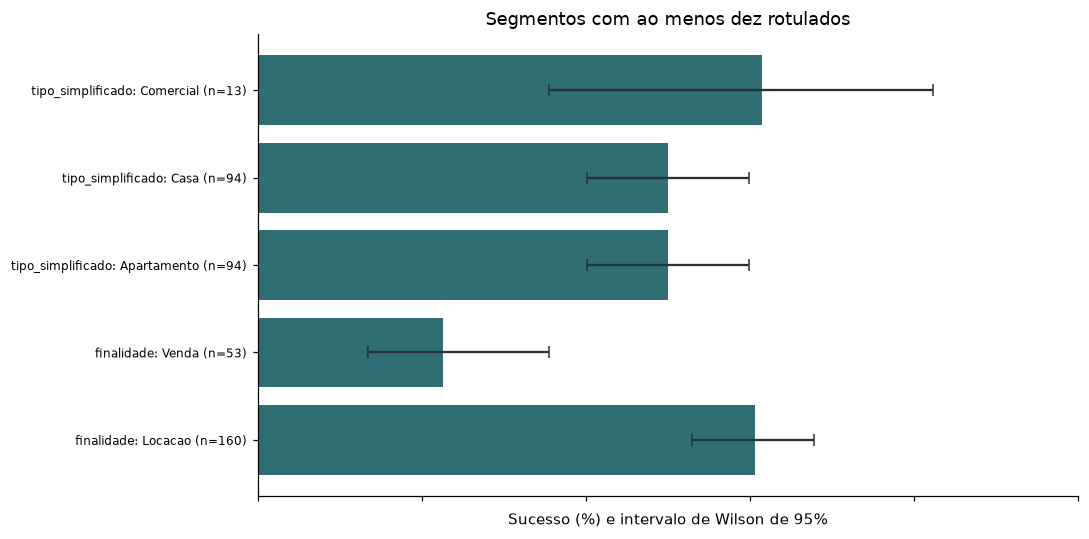

| finalidade | sucesso_comercial | count | median | mean |
| --- | --- | --- | --- | --- |
| Locação | 0.000 | 63 | 2550.000 | 5913.492 |
| Locação | 1.000 | 97 | 2400.000 | 3960.206 |
| Venda | 0.000 | 41 | 395000.000 | 673192.683 |
| Venda | 1.000 | 12 | 465000.000 | 867375.000 |

In [27]:
segments = []
for column in ["finalidade", "tipo_simplificado", "bairro", "cidade", "zona", "regiao"]:
    for category, group in labeled_df.groupby(column, dropna=False):
        total = len(group)
        successes = int(group.sucesso_comercial.sum())
        rate = successes/total
        z = 1.96
        center = (rate+z*z/(2*total))/(1+z*z/total)
        half = z*np.sqrt(rate*(1-rate)/total+z*z/(4*total*total))/(1+z*z/total)
        segments.append({"variavel":column, "segmento":str(category) if pd.notna(category) else "<ausente>",
                         "n":total,"sucessos":successes,"taxa_pct":100*rate,
                         "ic95_inferior_pct":100*(center-half),"ic95_superior_pct":100*(center+half),
                         "baixo_volume":total<10})
segment_summary = pd.DataFrame(segments)
show_table("segmentacoes", segment_summary)
plot_segments = segment_summary[(segment_summary.variavel.isin(["finalidade","tipo_simplificado"])) & ~segment_summary.baixo_volume]
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(plot_segments))
ax.barh(y, plot_segments.taxa_pct, color="#2f6f73")
ax.errorbar(plot_segments.taxa_pct, y,
            xerr=np.maximum(0, np.array([plot_segments.taxa_pct-plot_segments.ic95_inferior_pct,
                           plot_segments.ic95_superior_pct-plot_segments.taxa_pct])), fmt="none", ecolor="#263238", capsize=4)
ax.set_yticks(y, [f"{r.variavel}: {r.segmento} (n={r.n})" for r in plot_segments.itertuples()], fontsize=8)
ax.set(xlim=(0,100), xlabel="Sucesso (%) e intervalo de Wilson de 95%", title="Segmentos com ao menos dez rotulados")
show_figure(fig)
show_table("precos_por_finalidade_e_alvo", labeled_df.groupby(["finalidade","sucesso_comercial"])["valor_num"].agg(["count","median","mean"]).reset_index())

## 13. Padrões temporais dos contatos

A série usa as datas dos **contatos brutos**, incluindo contatos sem código de imóvel, pois a pergunta é sobre a demanda registrada. Meses sem registros entre a primeira e a última data são preenchidos com zero. Primeiro e último mês podem estar incompletos; lacunas também podem refletir falhas de coleta. Dia da semana e hora são volumes brutos, sem ajuste pela exposição. Não existe data confiável de venda/locação: estes gráficos não medem fechamento, duração de negociação nem demonstram sazonalidade.

Período: 2024-06-30 09:54:04 a 2026-05-30 19:08:04; 0 datas ausentes/inválidas de 4576 contatos.


| mes | contatos |
| --- | --- |
| 2024-06 | 3 |
| 2024-07 | 95 |
| 2024-08 | 238 |
| 2024-09 | 287 |
| 2024-10 | 385 |
| 2024-11 | 221 |
| 2024-12 | 191 |
| 2025-01 | 465 |
| 2025-02 | 286 |
| 2025-03 | 155 |
| 2025-04 | 292 |
| 2025-05 | 214 |
| 2025-06 | 136 |
| 2025-07 | 167 |
| 2025-08 | 186 |
| 2025-09 | 157 |
| 2025-10 | 94 |
| 2025-11 | 82 |
| 2025-12 | 86 |
| 2026-01 | 105 |
| 2026-02 | 111 |
| 2026-03 | 131 |
| 2026-04 | 294 |
| 2026-05 | 195 |

| dia | contatos |
| --- | --- |
| segunda | 833 |
| terca | 748 |
| quarta | 740 |
| quinta | 662 |
| sexta | 635 |
| sabado | 458 |
| domingo | 500 |

| hora | contatos |
| --- | --- |
| 0 | 123 |
| 1 | 58 |
| 2 | 38 |
| 3 | 25 |
| 4 | 14 |
| 5 | 23 |
| 6 | 68 |
| 7 | 96 |
| 8 | 162 |
| 9 | 242 |
| 10 | 249 |
| 11 | 304 |
| 12 | 318 |
| 13 | 311 |
| 14 | 342 |
| 15 | 302 |
| 16 | 284 |
| 17 | 285 |
| 18 | 232 |
| 19 | 239 |
| 20 | 250 |
| 21 | 247 |
| 22 | 226 |
| 23 | 138 |

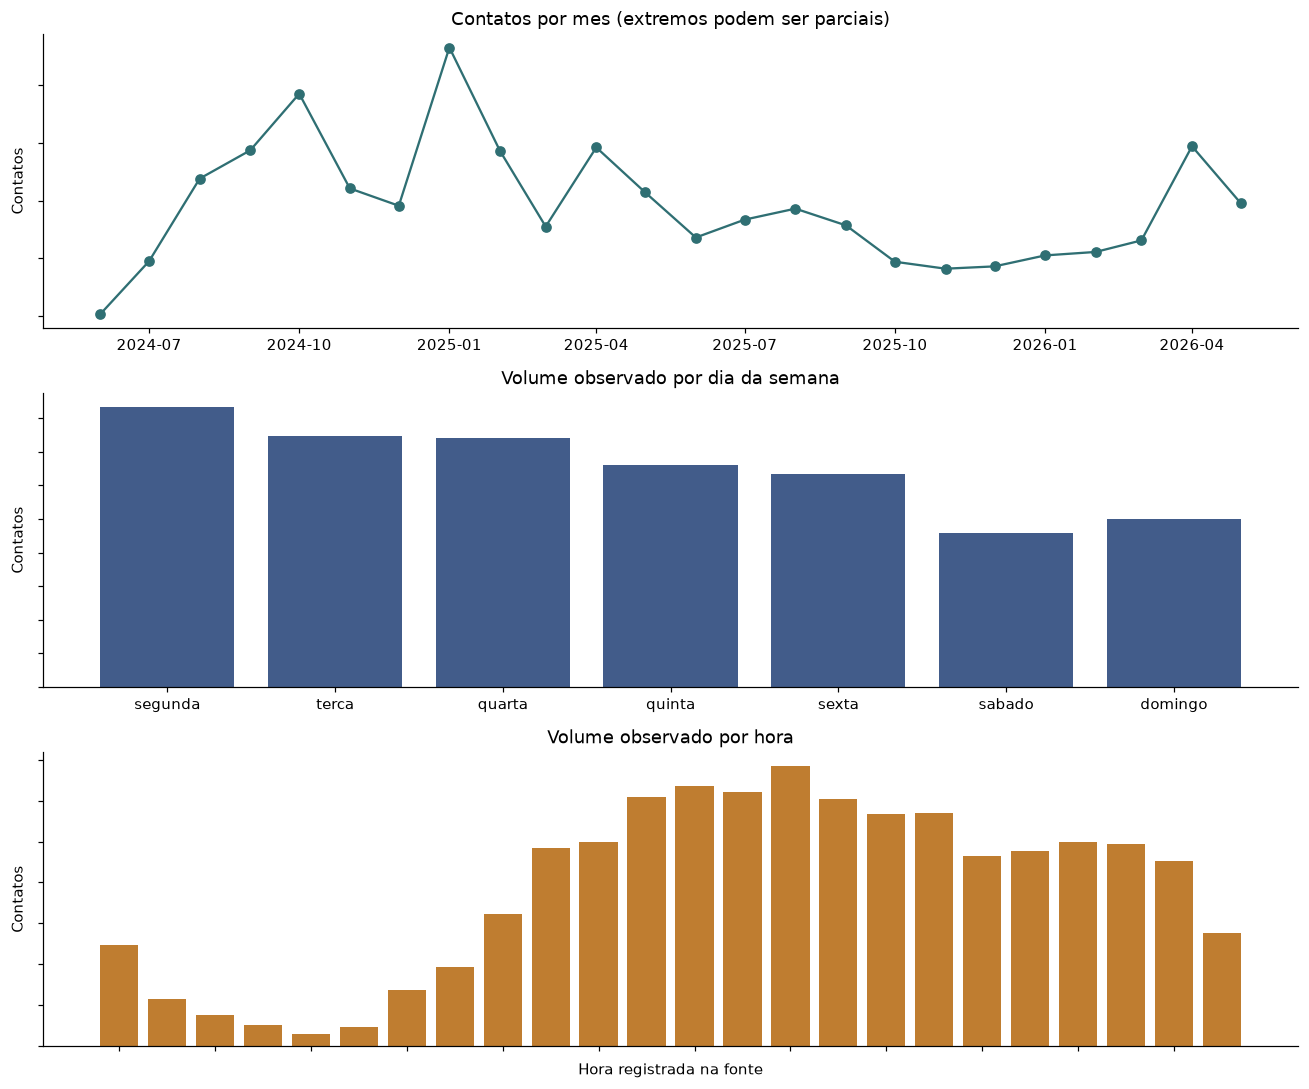

In [28]:
contact_dates = pd.Series([parse_datetime_pt(row.get("Data", "")) for row in contatos], dtype="datetime64[ns]")
valid_dates = contact_dates.dropna()
invalid_dates = int(contact_dates.isna().sum())
if valid_dates.empty:
    raise ValueError("Não há datas válidas de contato para a análise temporal.")
periods = valid_dates.dt.to_period("M")
monthly = periods.value_counts().sort_index().reindex(pd.period_range(periods.min(), periods.max(), freq="M"), fill_value=0)
monthly_table = pd.DataFrame({"mes":monthly.index.astype(str), "contatos":monthly.values})
show_table("contatos_mensais", monthly_table)
weekday = valid_dates.dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
hour = valid_dates.dt.hour.value_counts().reindex(range(24), fill_value=0)
show_table("contatos_dia_semana", pd.DataFrame({"dia":[WEEKDAY_PT[i] for i in range(7)], "contatos":weekday.values}))
show_table("contatos_hora", pd.DataFrame({"hora":hour.index, "contatos":hour.values}))
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].plot(monthly.index.to_timestamp(), monthly.values, marker="o", color="#2f6f73")
axes[0].set(title="Contatos por mês (extremos podem ser parciais)", ylabel="Contatos")
axes[1].bar([WEEKDAY_PT[i] for i in range(7)], weekday.values, color="#425c8a")
axes[1].set(title="Volume observado por dia da semana", ylabel="Contatos")
axes[2].bar(hour.index, hour.values, color="#bf7d30")
axes[2].set(title="Volume observado por hora", xlabel="Hora registrada na fonte", ylabel="Contatos", xticks=range(0,24,2))
show_figure(fig)
print(f"Período: {valid_dates.min()} a {valid_dates.max()}; {invalid_dates} datas ausentes/inválidas de {len(contatos)} contatos.")

## 14. Principais achados e conclusões

Síntese das evidências, limitações e pontos a investigar.

In [29]:
zero_contacts = int(df.total_contatos.eq(0).sum())
strongest = association.dropna(subset=["spearman"]).iloc[0] if association.spearman.notna().any() else None
purpose_segments = segment_summary[segment_summary.variavel.eq("finalidade")]
purpose_evidence = "; ".join(f"{r.segmento}: {r.taxa_pct:.1f}% (n={r.n})" for r in purpose_segments.itertuples())
peak_month = monthly.idxmax()
insight_rows = [
    ["Base e alvo", f"{len(df)} imóveis; {len(labeled_df)} rotulados; {int(df.sucesso_comercial.isna().sum())} sem rótulo.",
     "Sem rótulo não equivale a fracasso.", "Analisar imóveis com e sem desfecho separadamente."],
    ["Referências repetidas", f"{duplicate_rows} linhas compartilham {duplicate_refs} referências repetidas.",
     "Linhas não são necessariamente imóveis independentes.", "Validar finalidade e unidade de análise para evitar dupla contagem."],
    ["Qualidade", f"{int(quality.ausentes_pct.eq(100).sum())} colunas completamente ausentes; {int(df.valor_num.isna().sum())} preços ausentes.",
     "Zeros extraídos de características podem significar ausência.", "Revisar a captura e distinguir ausência de informação de zero real."],
    ["Demanda observada", f"{zero_contacts}/{len(df)} imóveis sem contatos vinculados ({zero_contacts/len(df):.1%}).",
     "Contato sem código e falhas de vínculo podem ocultar demanda.", "Validar a cobertura e o vínculo entre contatos e imóveis."],
    ["Finalidades", purpose_evidence,
     "Mistura de períodos, tipos e tamanhos amostrais.", "Comparar os resultados separadamente por finalidade."],
    ["Outliers", f"{int(outlier_summary.outliers.sum())} preços sinalizados em {int(outlier_summary.avaliado.sum())} grupos avaliáveis.",
     "Regra IQR não comprova erro; grupos pequenos não foram avaliados.", "Conferir valores extremos com a empresa, sem exclusão automática."],
    ["Temporalidade", f"Pico observado: {peak_month}, {int(monthly.max())} contatos; {invalid_dates} datas inválidas/ausentes.",
     "Meses extremos parciais; volume não demonstra sazonalidade ou fechamento.", "Validar período e completude da coleta antes de comparar meses."],

]
if strongest is not None:
    insight_rows.insert(4,["Associação com o alvo", f"Maior |Spearman| avaliado: {strongest['variavel']} = {strongest.spearman:.3f} (n={int(strongest.n_pares)}).",
                          "Associação exploratória, sem causalidade; verificar vazamento.", "Investigar a relação por finalidade e verificar a sequência temporal dos contatos."])
insights_df = pd.DataFrame(insight_rows, columns=["tema","evidencia","limitacao","decisao_proposta"])
show_table("insights_eda", insights_df)
summary = "# Conclusões da EDA\n\n" + "\n".join(
    f"- **{r.tema}:** {r.evidencia} Decisão: {r.decisao_proposta}" for r in insights_df.itertuples())
display(Markdown(summary))


| tema | evidencia | limitacao | decisao_proposta |
| --- | --- | --- | --- |
| Base e alvo | 467 imóveis; 213 rotulados; 254 sem rótulo. | Sem rótulo não equivale a fracasso. | Analisar imóveis com e sem desfecho separadamente. |
| Referências repetidas | 46 linhas compartilham 23 referências repetidas. | Linhas não são necessariamente imóveis independentes. | Validar finalidade e unidade de análise para evitar dupla contagem. |
| Qualidade | 1 colunas completamente ausentes; 1 preços ausentes. | Zeros extraídos de características podem significar ausência. | Revisar a captura e distinguir ausência de informação de zero real. |
| Demanda observada | 177/467 imóveis sem contatos vinculados (37.9%). | Contato sem código e falhas de vínculo podem ocultar demanda. | Validar a cobertura e o vínculo entre contatos e imóveis. |
| Associação com o alvo | Maior  / Spearman /  avaliado: total_contatos = 0.369 (n=213). | Associação exploratória, sem causalidade; verificar vazamento. | Investigar a relação por finalidade e verificar a sequência temporal dos contatos. |
| Finalidades | Locação: 60.6% (n=160); Venda: 22.6% (n=53) | Mistura de períodos, tipos e tamanhos amostrais. | Comparar os resultados separadamente por finalidade. |
| Outliers | 25 preços sinalizados em 7 grupos avaliáveis. | Regra IQR não comprova erro; grupos pequenos não foram avaliados. | Conferir valores extremos com a empresa, sem exclusão automática. |
| Temporalidade | Pico observado: 2025-01, 465 contatos; 0 datas inválidas/ausentes. | Meses extremos parciais; volume não demonstra sazonalidade ou fechamento. | Validar período e completude da coleta antes de comparar meses. |

# Conclusões da EDA

- **Base e alvo:** 467 imóveis; 213 rotulados; 254 sem rótulo. Decisão: Analisar imóveis com e sem desfecho separadamente.
- **Referências repetidas:** 46 linhas compartilham 23 referências repetidas. Decisão: Validar finalidade e unidade de análise para evitar dupla contagem.
- **Qualidade:** 1 colunas completamente ausentes; 1 preços ausentes. Decisão: Revisar a captura e distinguir ausência de informação de zero real.
- **Demanda observada:** 177/467 imóveis sem contatos vinculados (37.9%). Decisão: Validar a cobertura e o vínculo entre contatos e imóveis.
- **Associação com o alvo:** Maior |Spearman| avaliado: total_contatos = 0.369 (n=213). Decisão: Investigar a relação por finalidade e verificar a sequência temporal dos contatos.
- **Finalidades:** Locação: 60.6% (n=160); Venda: 22.6% (n=53) Decisão: Comparar os resultados separadamente por finalidade.
- **Outliers:** 25 preços sinalizados em 7 grupos avaliáveis. Decisão: Conferir valores extremos com a empresa, sem exclusão automática.
- **Temporalidade:** Pico observado: 2025-01, 465 contatos; 0 datas inválidas/ausentes. Decisão: Validar período e completude da coleta antes de comparar meses.